# Employee Attrition Prediction – Decision Tree, Bagging, Random Forest & Boosting


# 1. Import Libraries

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"      # set to your actual CPU core count

import warnings
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
%matplotlib inline

# 2. Load Data

In [2]:
df = pd.read_csv("HR.csv")

# 3. Basic Checks

### 3.1 First Look at the Data

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 3.2 Data Types & Null Values

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### 3.3 Statistics – Numerical Columns

In [5]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### 3.4 Statistics – Categorical Columns

In [6]:
df.describe(include='O')

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


# 4. Data Cleaning & Feature Selection

### 4.1 Drop Useless Columns
These columns have zero variance (same value for every row) or are just an ID, so they carry no information.

In [7]:
df.drop(['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber'], axis=1, inplace=True)

### 4.2 Correlation Check
Highly correlated features give the same information twice, so one of them is removed.

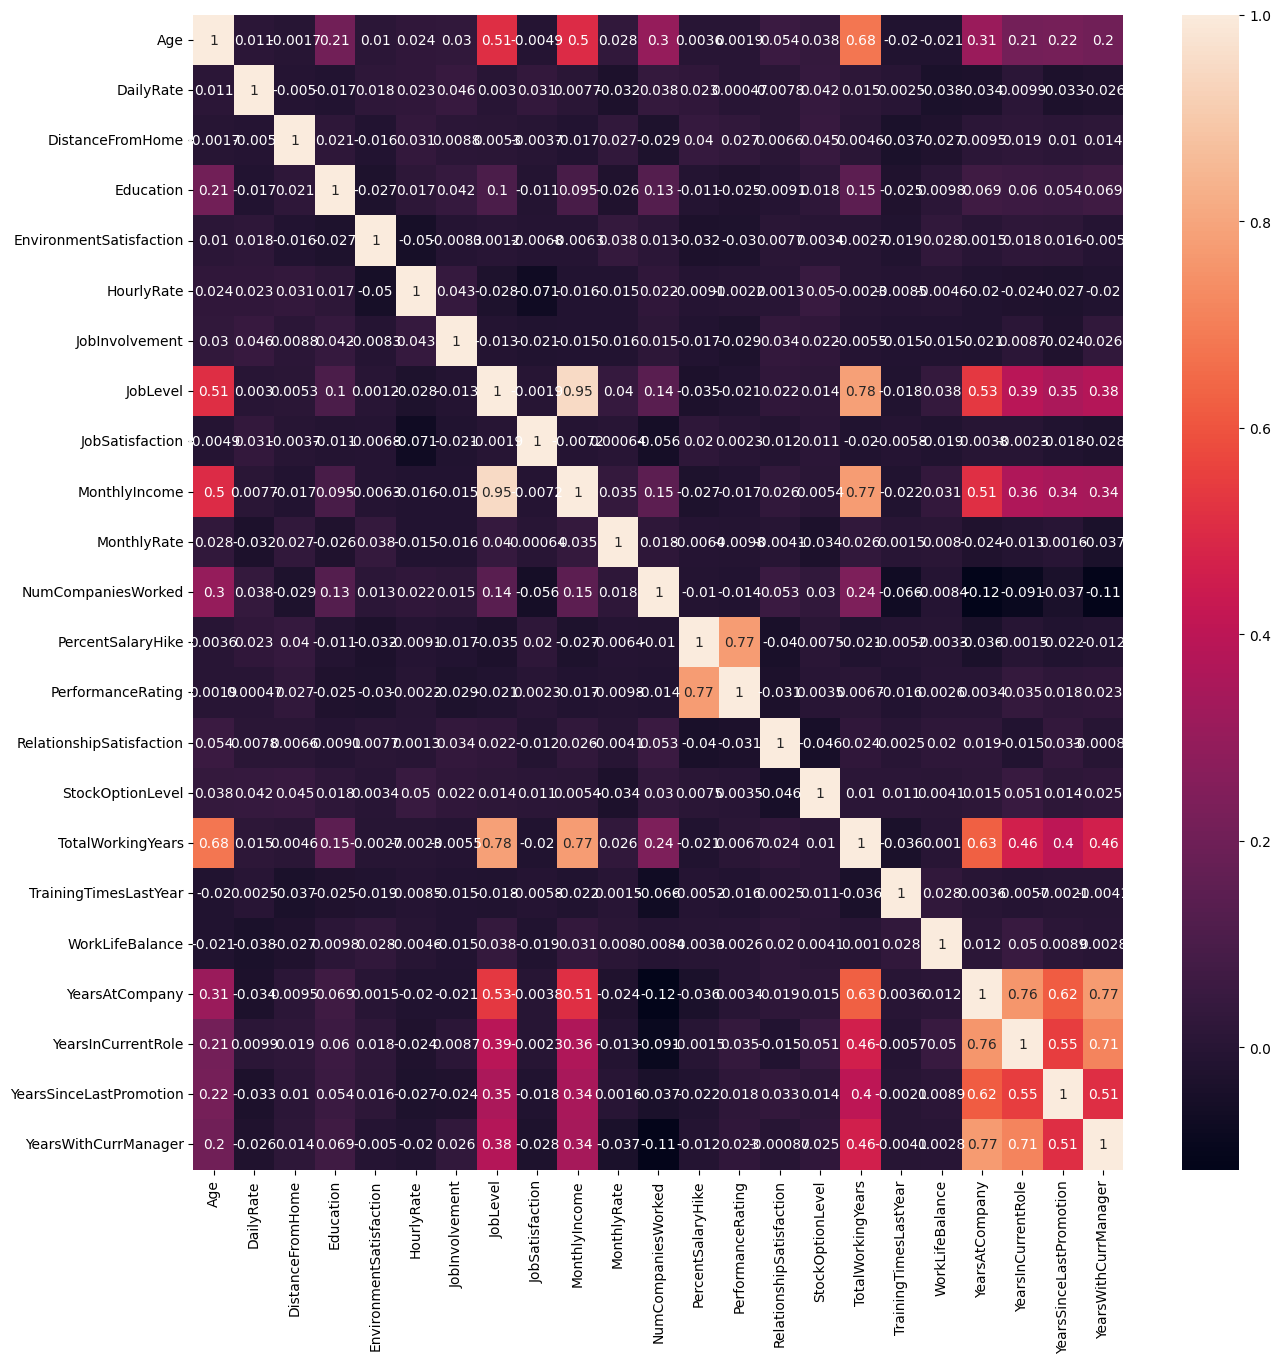

In [8]:
plt.figure(figsize=(15, 15))
sns.heatmap(df.select_dtypes(include=['int', 'float']).corr(), annot=True)
plt.show()

In [9]:
df.drop('MonthlyIncome', axis=1, inplace=True)     # highly correlated with JobLevel

### 4.3 Unique Values Summary

# 5. Preprocessing Setup (Column Transformer)
Each group of columns gets the treatment that suits it.

In [10]:
OHE_columns    = ['BusinessTravel', 'Department', 'MaritalStatus', 'EducationField', 'Gender', 'JobRole']   # nominal categories -> One-Hot
ordinal_column = ['OverTime']                                                                              # Yes/No -> 0/1
scale_columns  = ['Age', 'DailyRate', 'DistanceFromHome', 'MonthlyRate', 'HourlyRate', 'NumCompaniesWorked',
                  'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
                  'YearsWithCurrManager', 'PercentSalaryHike']                                             # continuous -> StandardScaler
# All remaining columns (small rating-type numbers) are passed through unchanged

preprocessor = ColumnTransformer([
    ("OHE columns",     OneHotEncoder(),  OHE_columns),
    ("ordinal_encoder", OrdinalEncoder(), ordinal_column),
    ("Standard_scaler", StandardScaler(), scale_columns)
], remainder='passthrough')

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('OHE columns', OneHotEncoder(),
                                 ['BusinessTravel', 'Department',
                                  'MaritalStatus', 'EducationField', 'Gender',
                                  'JobRole']),
                                ('ordinal_encoder', OrdinalEncoder(),
                                 ['OverTime']),
                                ('Standard_scaler', StandardScaler(),
                                 ['Age', 'DailyRate', 'DistanceFromHome',
                                  'MonthlyRate', 'HourlyRate',
                                  'NumCompaniesWorked', 'TotalWorkingYears',
                                  'YearsAtCompany', 'YearsInCurrentRole',
                                  'YearsSinceLastPromotion',
                                  'YearsWithCurrManager',
                                  'PercentSalaryHike'])])

# 6. Train-Test Split

In [11]:
x = df.drop("Attrition", axis=1)                        # features
y = df["Attrition"].map({"No": 0, "Yes": 1})            # target converted to 0 / 1

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Train:", x_train.shape, " Test:", x_test.shape)

Train: (1176, 29)  Test: (294, 29)


# 7. Apply Preprocessing & Balance the Data (SMOTE)
* The preprocessor is **fitted on training data only** and then applied to test data (avoids data leakage).
* **SMOTE** balances the classes and is applied **only on training data**.

In [12]:
processed_x_train = preprocessor.fit_transform(x_train)
processed_x_test  = preprocessor.transform(x_test)

print("Before SMOTE:", Counter(y_train))
x_sm, y_sm = SMOTE(random_state=42).fit_resample(processed_x_train, y_train)
print("After  SMOTE:", Counter(y_sm))

Before SMOTE: Counter({0: 978, 1: 198})
After  SMOTE: Counter({0: 978, 1: 978})


# 8. Model 1 – Decision Tree
A single tree that splits the data using simple if/else rules. Easy to understand but tends to overfit.

![dt](Decision_Tree.jpeg)

In [13]:
decision_tree_model = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
decision_tree_model.fit(x_sm, y_sm)

print("Train Accuracy:", accuracy_score(y_sm, decision_tree_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, decision_tree_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, decision_tree_model.predict(processed_x_test)))

Train Accuracy: 0.8844580777096115
Test  Accuracy: 0.7993197278911565

Classification Report

              precision    recall  f1-score   support

           0       0.89      0.87      0.88       255
           1       0.27      0.31      0.29        39

    accuracy                           0.80       294
   macro avg       0.58      0.59      0.59       294
weighted avg       0.81      0.80      0.80       294



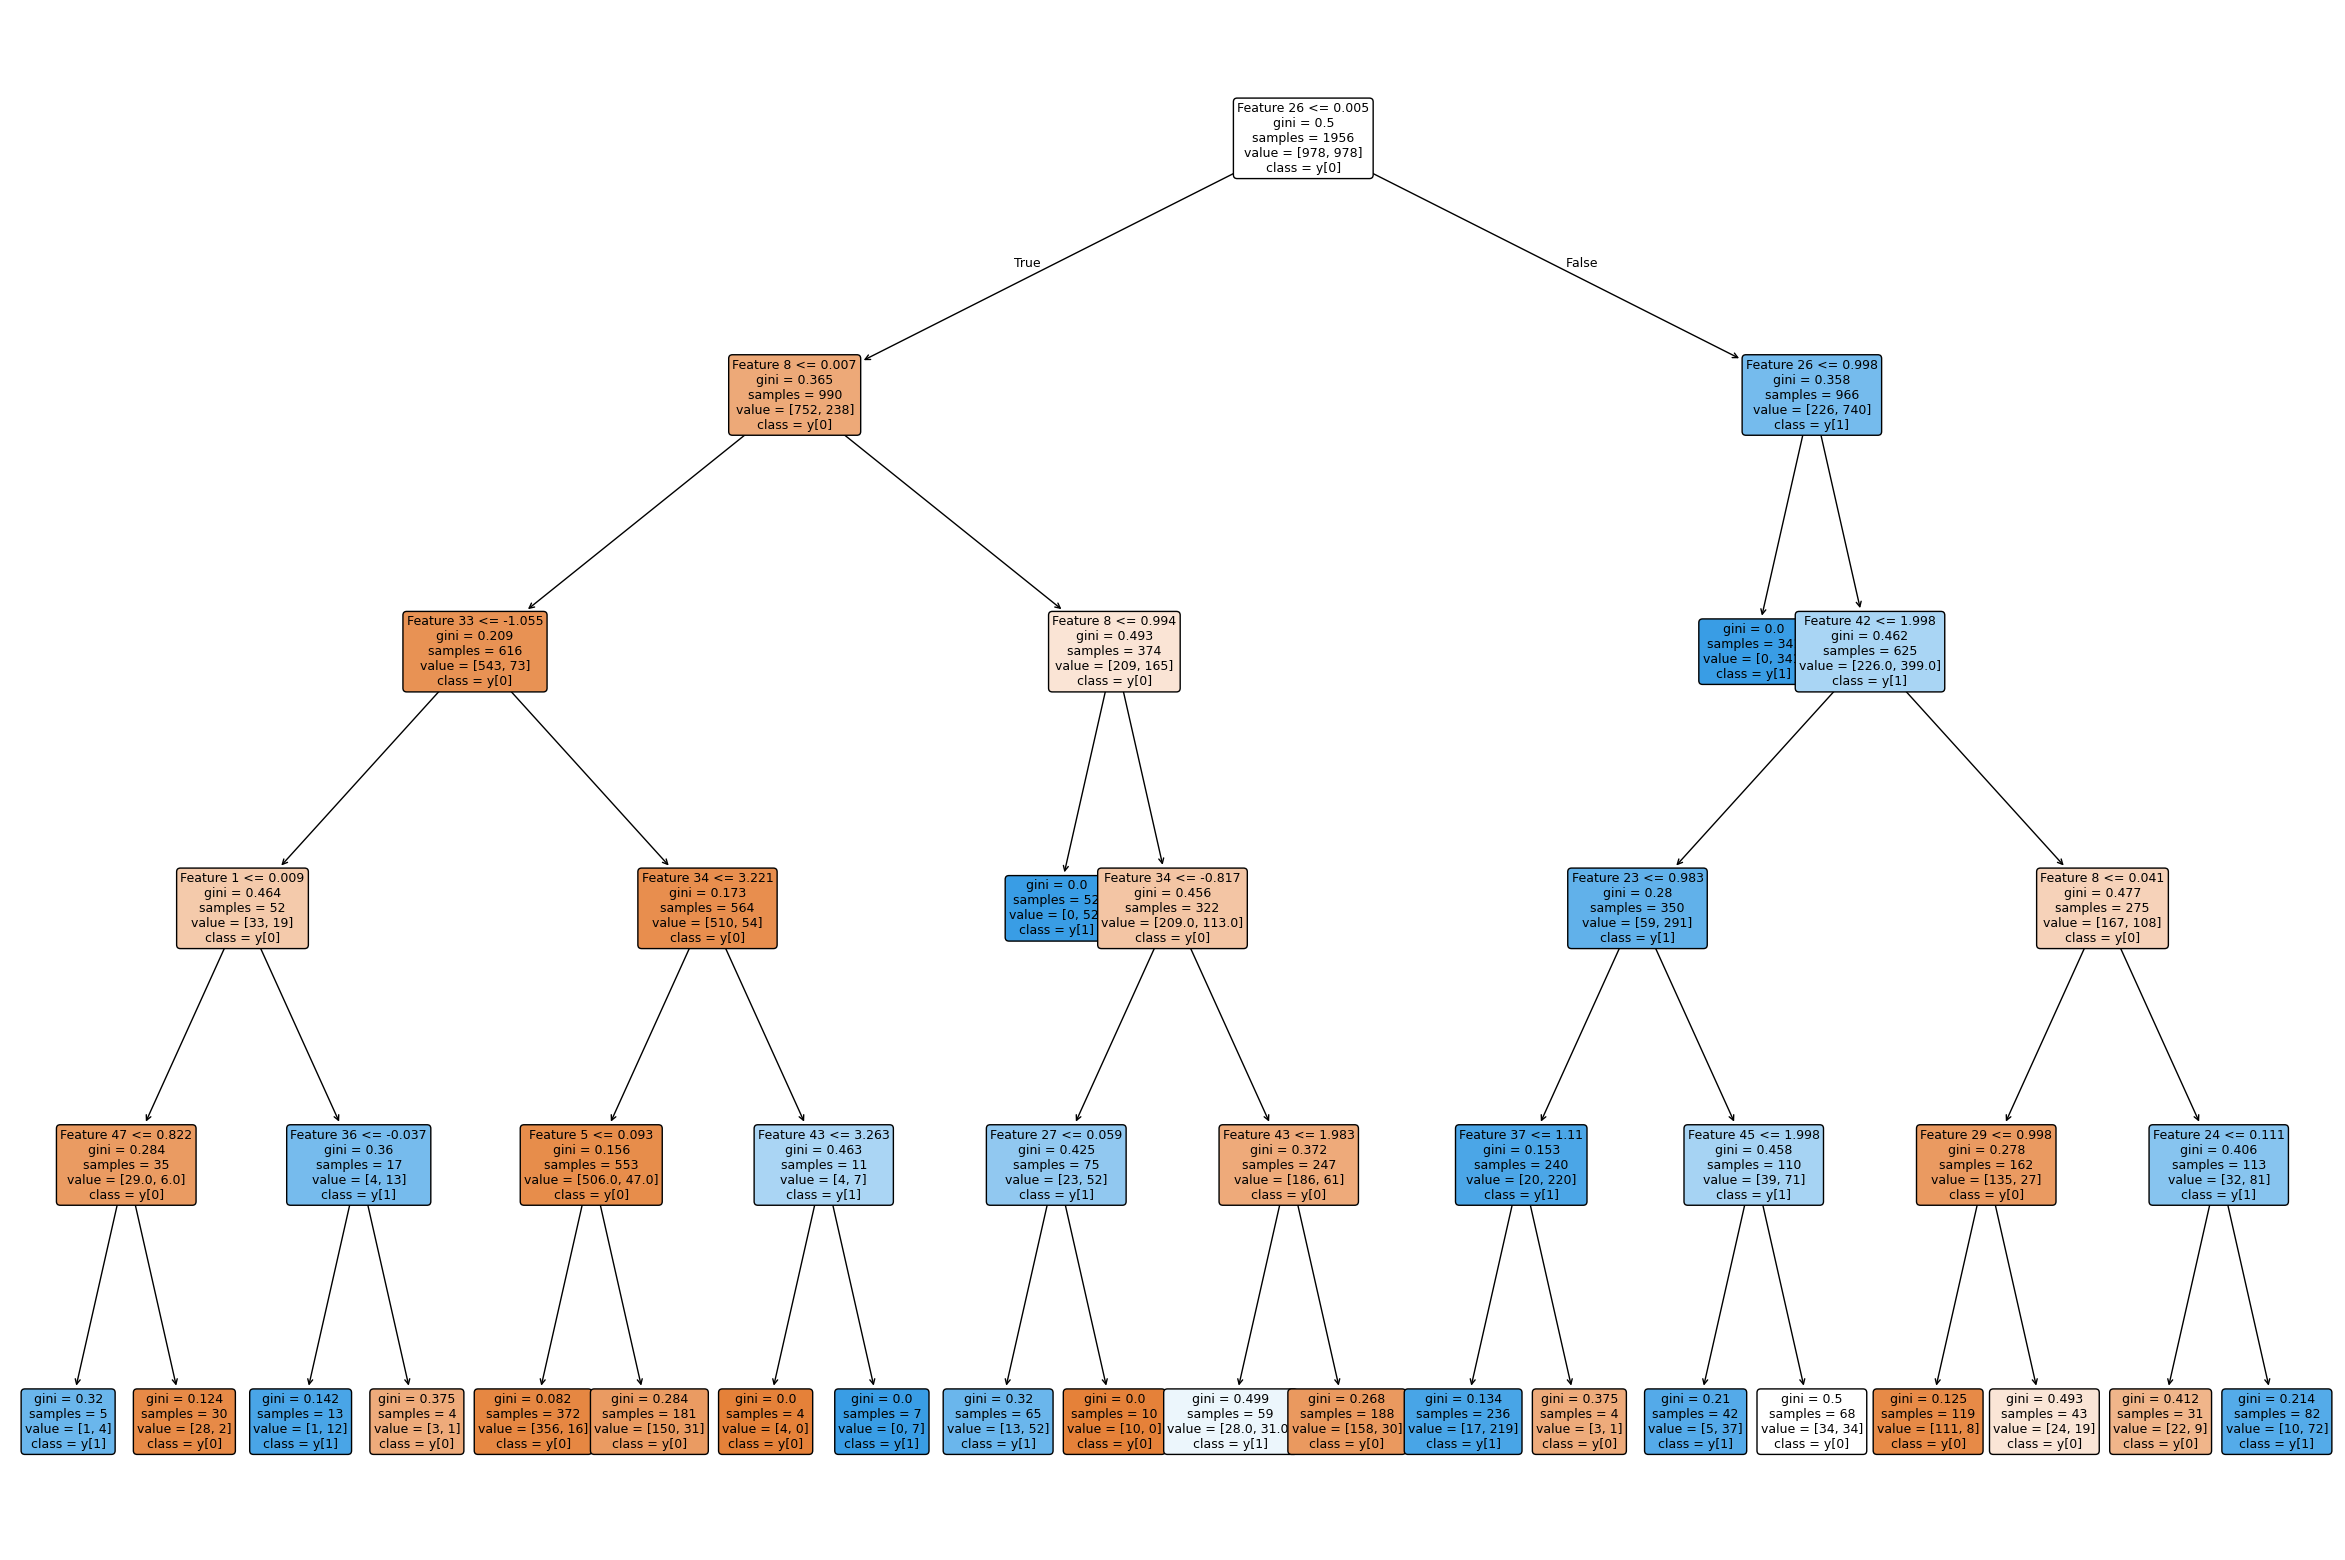

In [40]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(30, 20))

plot_tree(
    decision_tree_model,
    feature_names=decision_tree_model.feature_names_in_
        if hasattr(decision_tree_model, "feature_names_in_")
        else [f"Feature {i}" for i in range(x_sm.shape[1])],
    class_names=True,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()


# 9. Model 2 – Tuned Decision Tree (GridSearchCV)
Tries every combination of the hyper-parameters below with 5-fold cross-validation and keeps the best one.

![Hyper](hyper_paramater.jpeg)

In [14]:
params = {'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, 10]}

grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid=params, cv=5, scoring='accuracy')
grid_search.fit(x_sm, y_sm)
print("Best Parameters:", grid_search.best_params_)

tuned_dt_model = grid_search.best_estimator_

print("\nTrain Accuracy:", accuracy_score(y_sm, tuned_dt_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, tuned_dt_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, tuned_dt_model.predict(processed_x_test)))

Best Parameters: {'criterion': 'entropy', 'max_depth': 10}

Train Accuracy: 0.9815950920245399
Test  Accuracy: 0.8129251700680272

Classification Report

              precision    recall  f1-score   support

           0       0.89      0.90      0.89       255
           1       0.28      0.26      0.27        39

    accuracy                           0.81       294
   macro avg       0.58      0.58      0.58       294
weighted avg       0.81      0.81      0.81       294



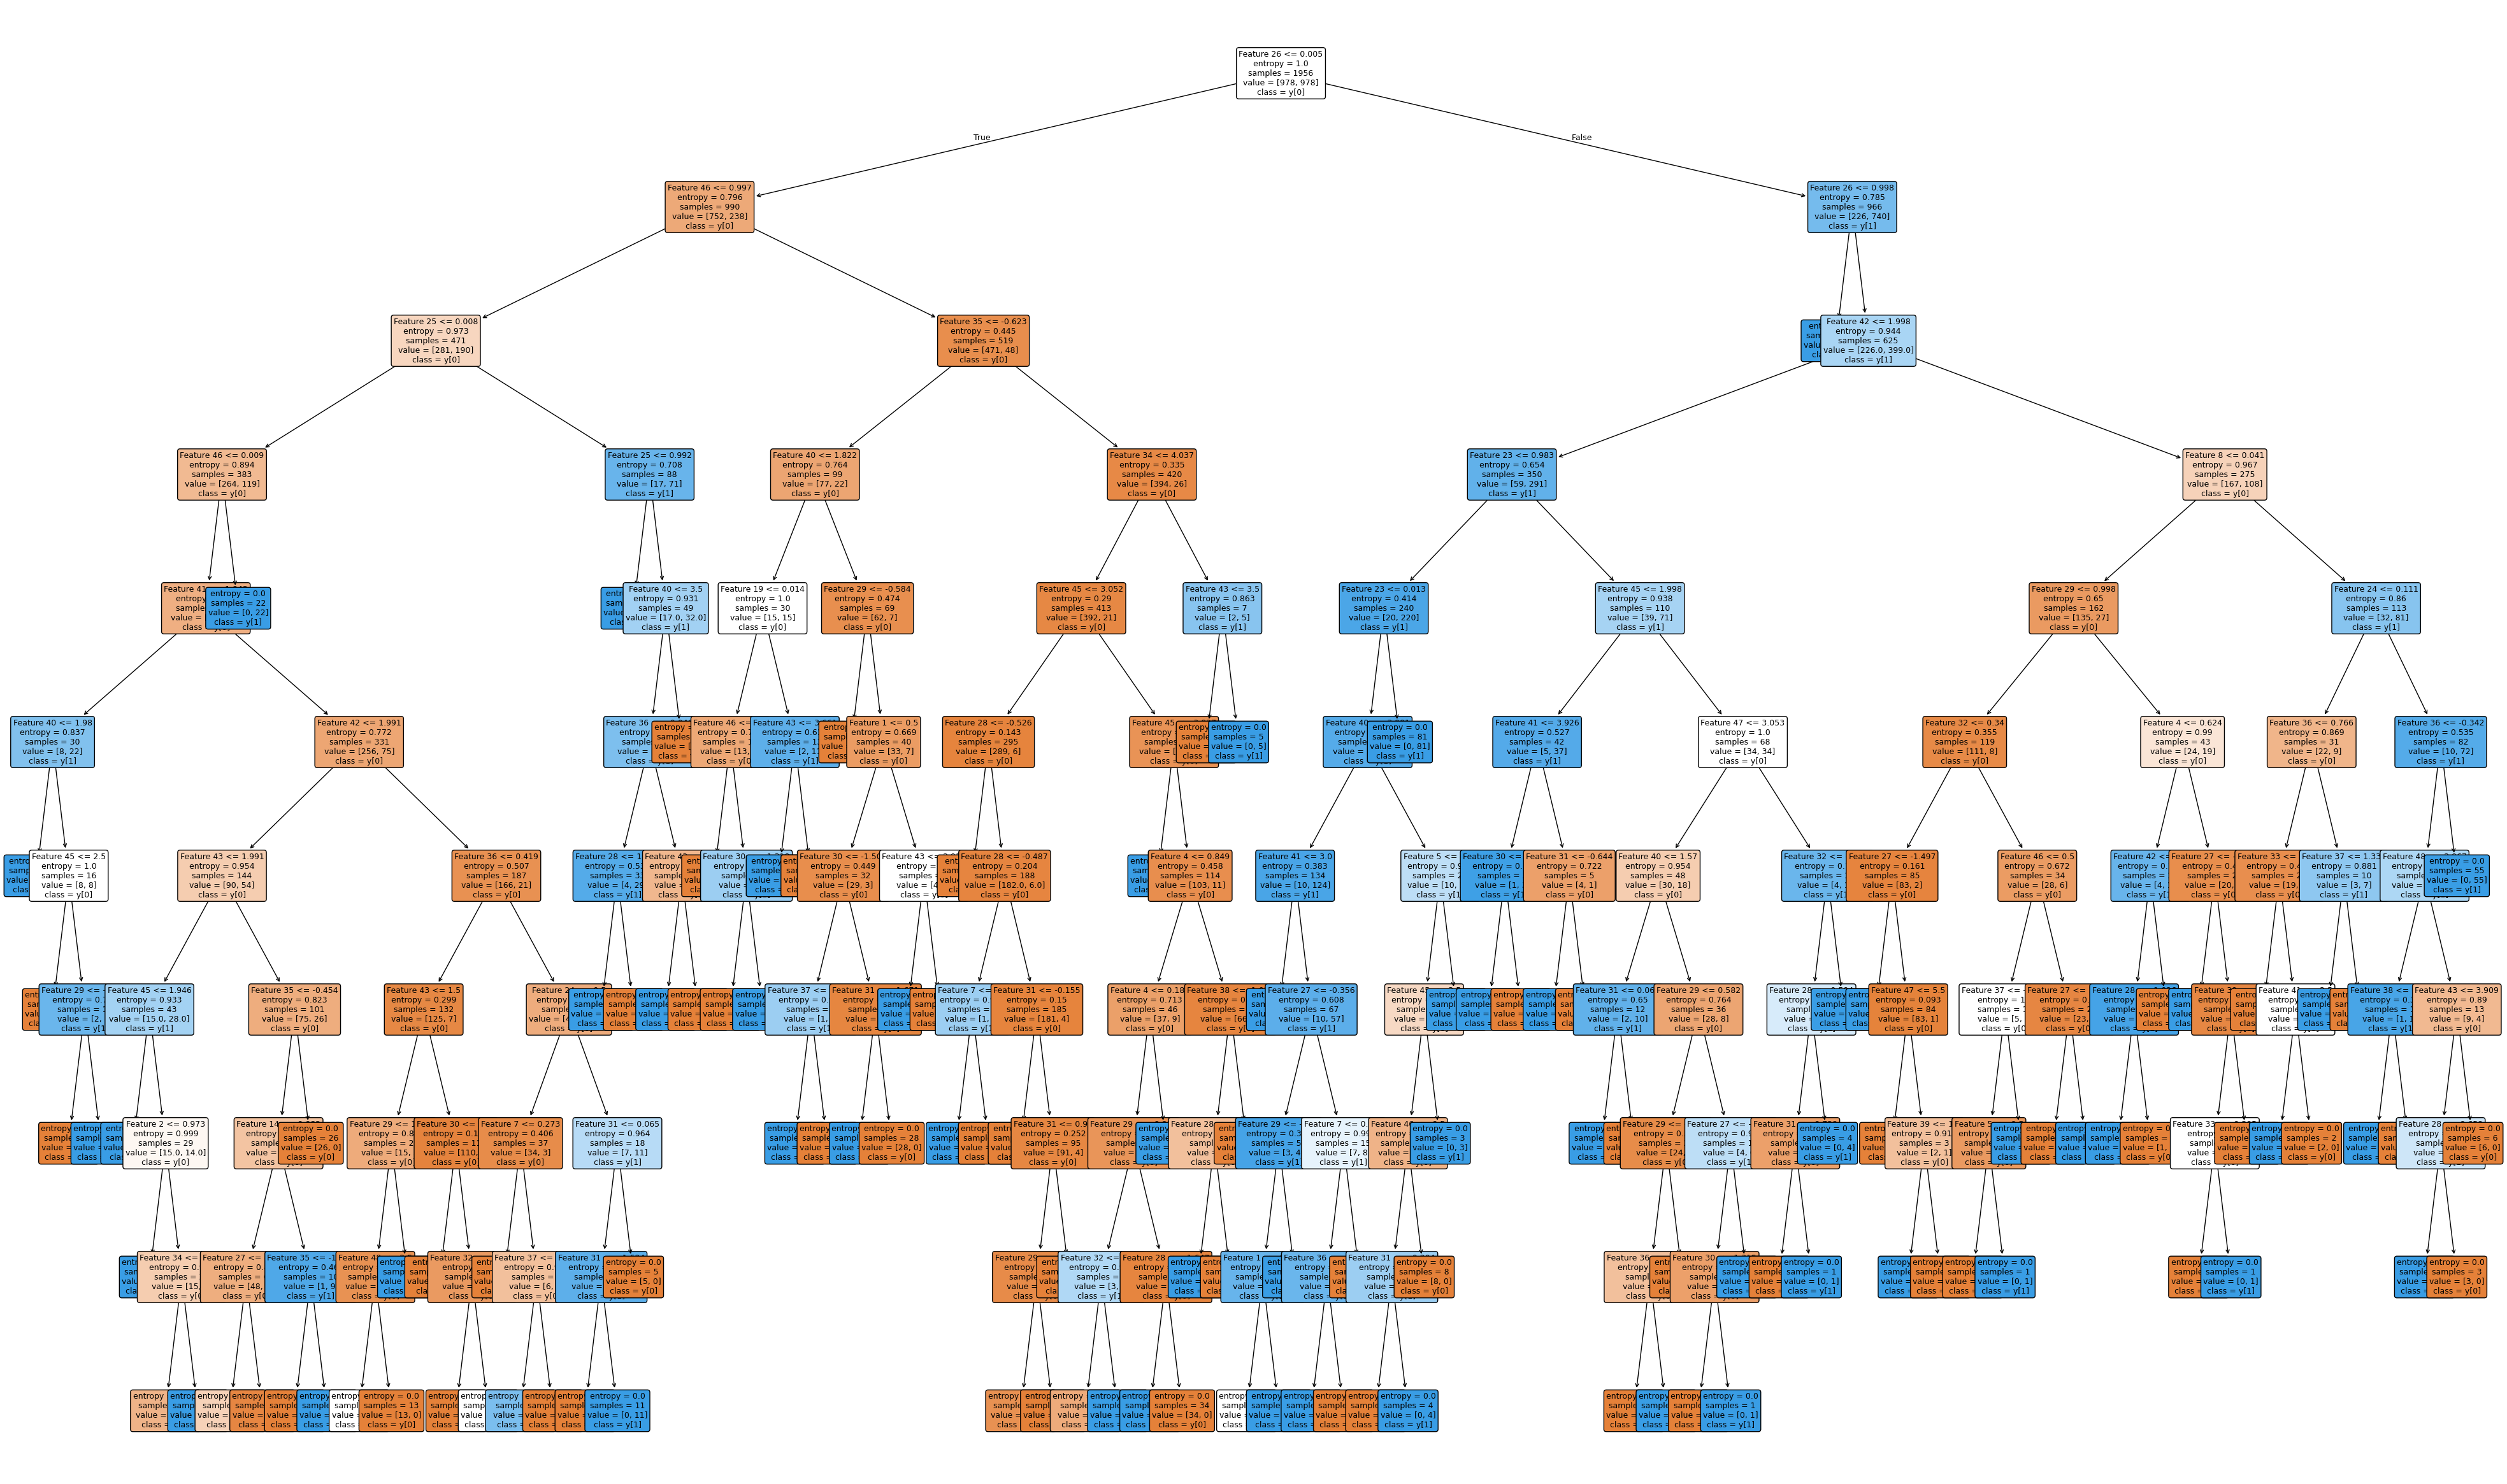

In [37]:
plt.figure(figsize=(50, 30))

plot_tree(
    tuned_dt_model,
    feature_names=tuned_dt_model.feature_names_in_
        if hasattr(tuned_dt_model, "feature_names_in_")
        else [f"Feature {i}" for i in range(x_sm.shape[1])],
    class_names=True,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()


# 10. Model 3 – Bagging
Trains many decision trees on random samples of the data (in parallel) and combines their votes. Reduces variance.

![Bagging Block Diagram](BAGGING.jpeg)

In [15]:
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, random_state=42)
bagging_model.fit(x_sm, y_sm)

print("Train Accuracy:", accuracy_score(y_sm, bagging_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, bagging_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, bagging_model.predict(processed_x_test)))

Train Accuracy: 1.0
Test  Accuracy: 0.8571428571428571

Classification Report

              precision    recall  f1-score   support

           0       0.89      0.95      0.92       255
           1       0.43      0.23      0.30        39

    accuracy                           0.86       294
   macro avg       0.66      0.59      0.61       294
weighted avg       0.83      0.86      0.84       294



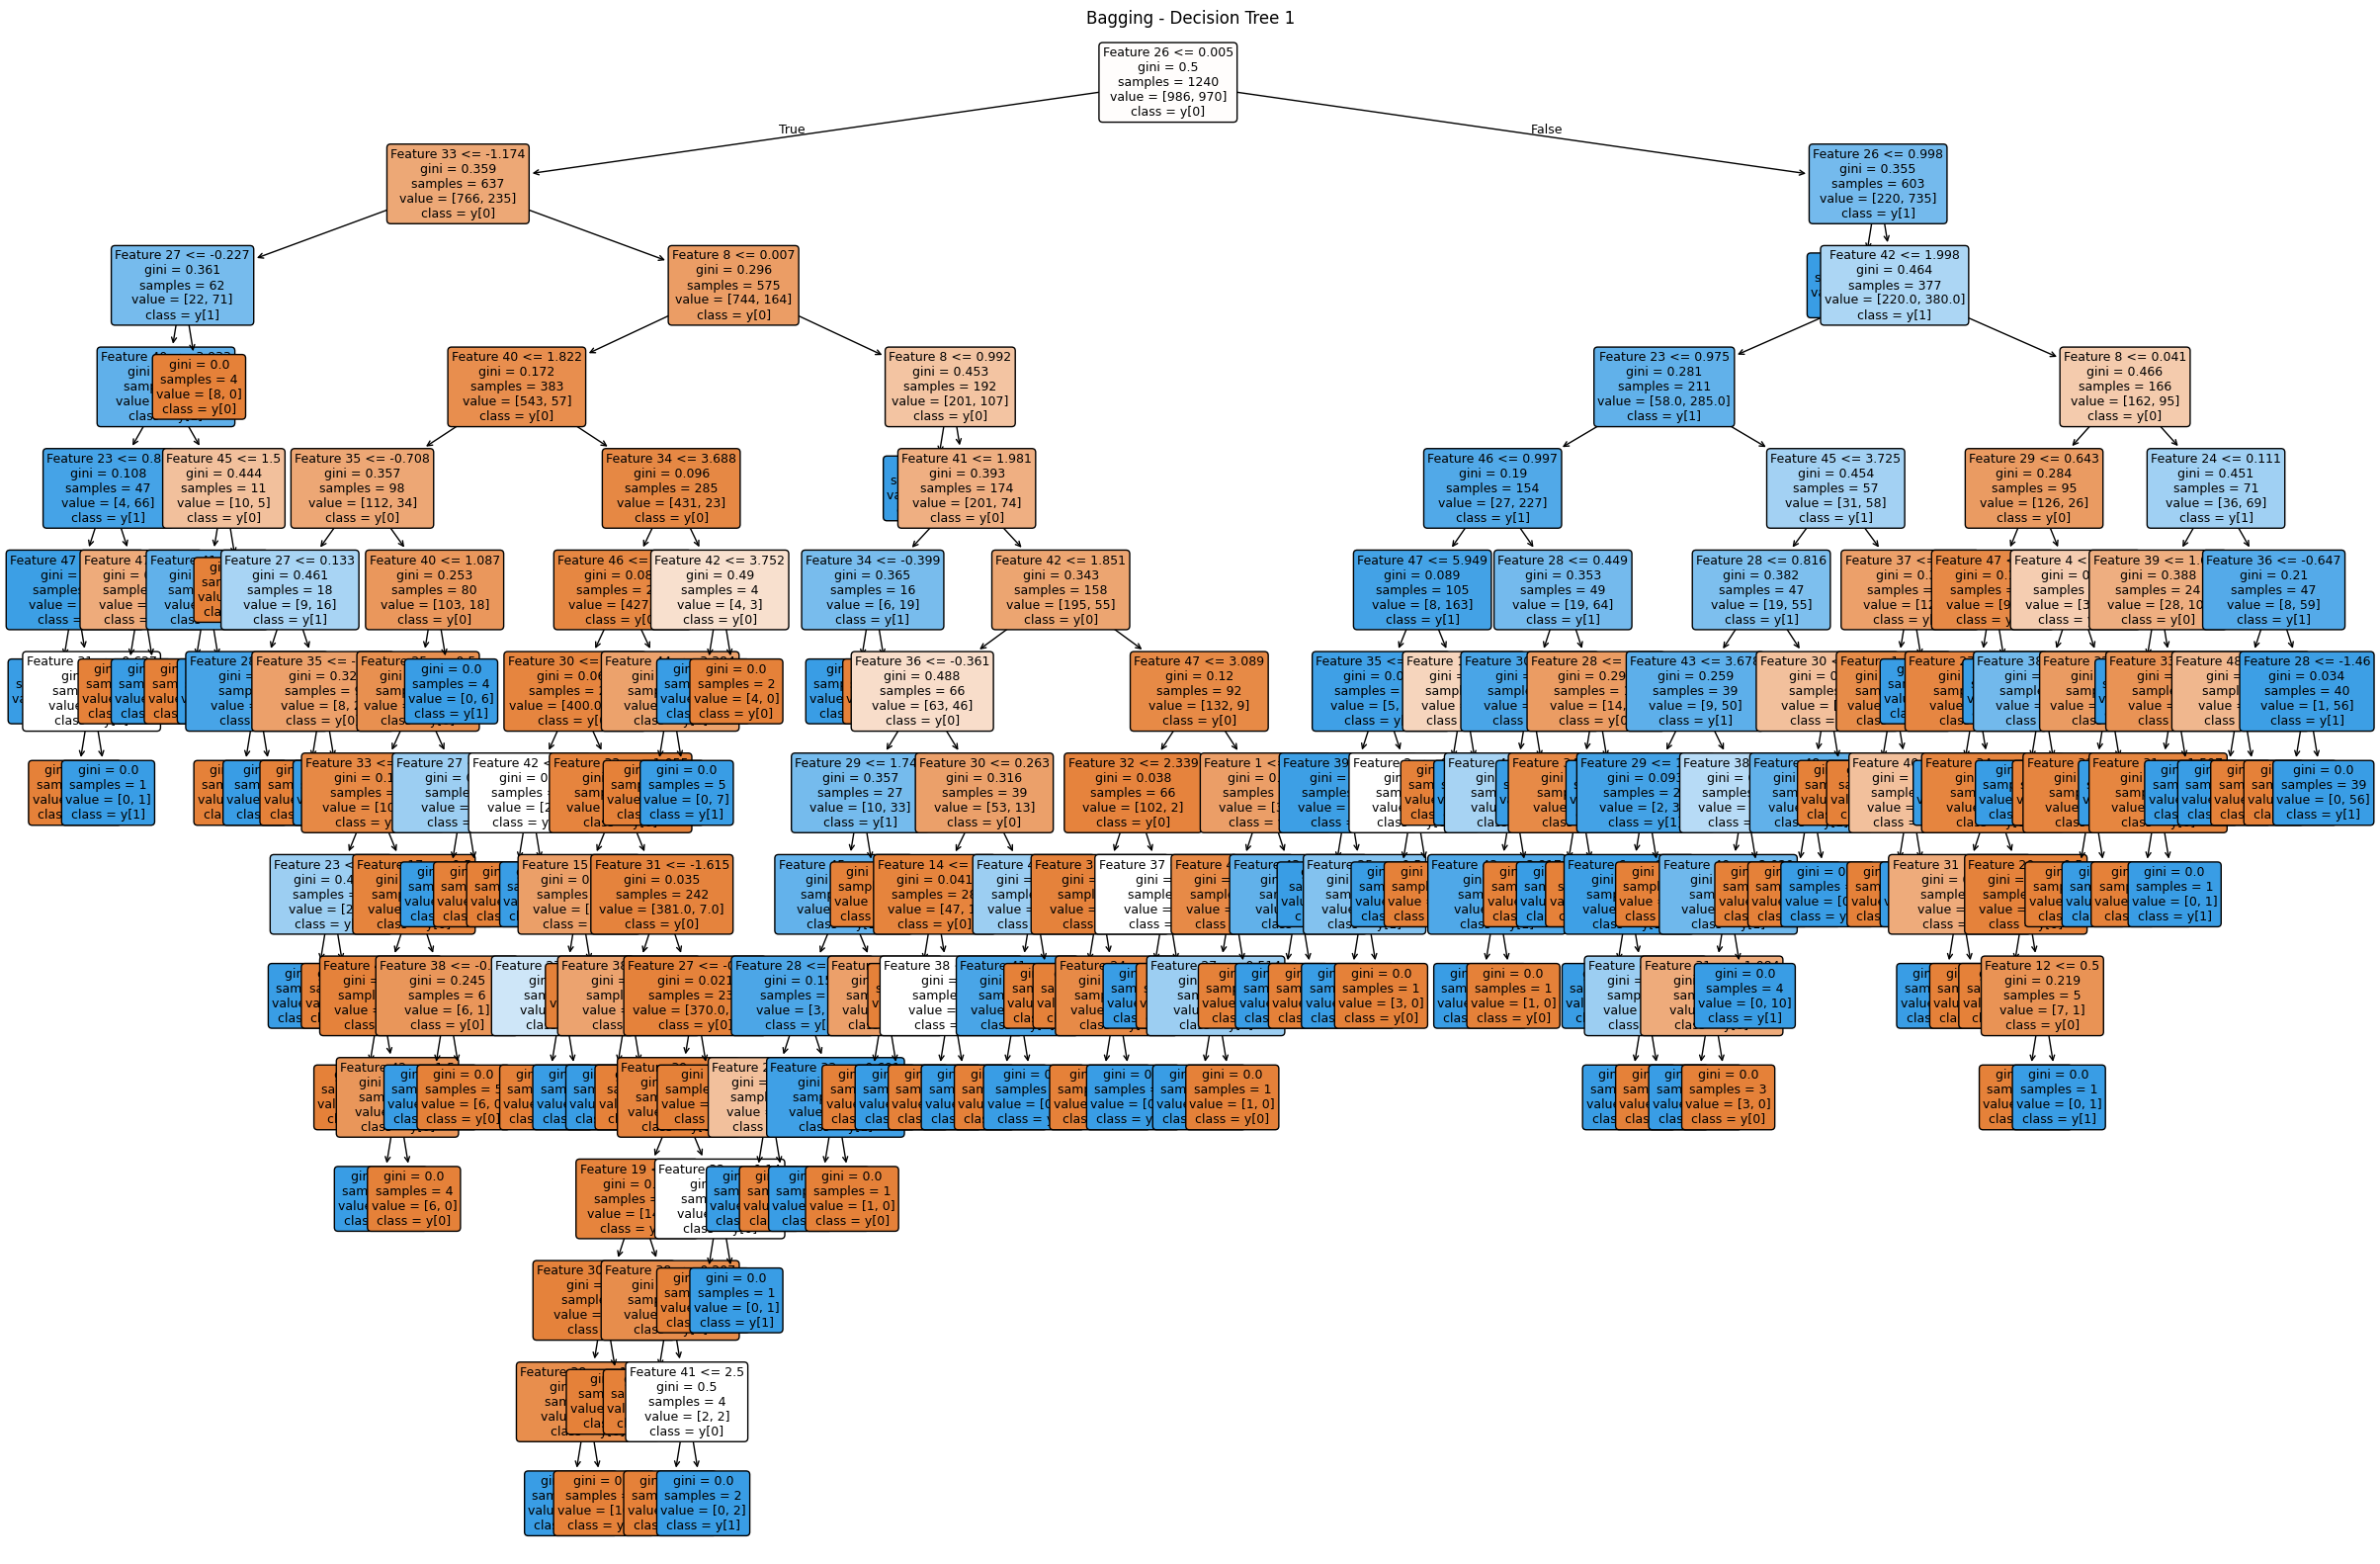

In [41]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(30, 20))

plot_tree(
    bagging_model.estimators_[0],
    feature_names=[f"Feature {i}" for i in range(x_sm.shape[1])],
    class_names=True,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Bagging - Decision Tree 1")
plt.show()


# 11. Model 4 – Random Forest
Bagging + random selection of features at each split, which makes the trees more different from each other and gives better generalization.

![Random Block Diagram](Random_forest.jpeg)

In [16]:
random_forest_model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
random_forest_model.fit(x_sm, y_sm)

print("Train Accuracy:", accuracy_score(y_sm, random_forest_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, random_forest_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, random_forest_model.predict(processed_x_test)))

Train Accuracy: 0.9197341513292433
Test  Accuracy: 0.8401360544217688

Classification Report

              precision    recall  f1-score   support

           0       0.89      0.93      0.91       255
           1       0.37      0.28      0.32        39

    accuracy                           0.84       294
   macro avg       0.63      0.60      0.61       294
weighted avg       0.82      0.84      0.83       294



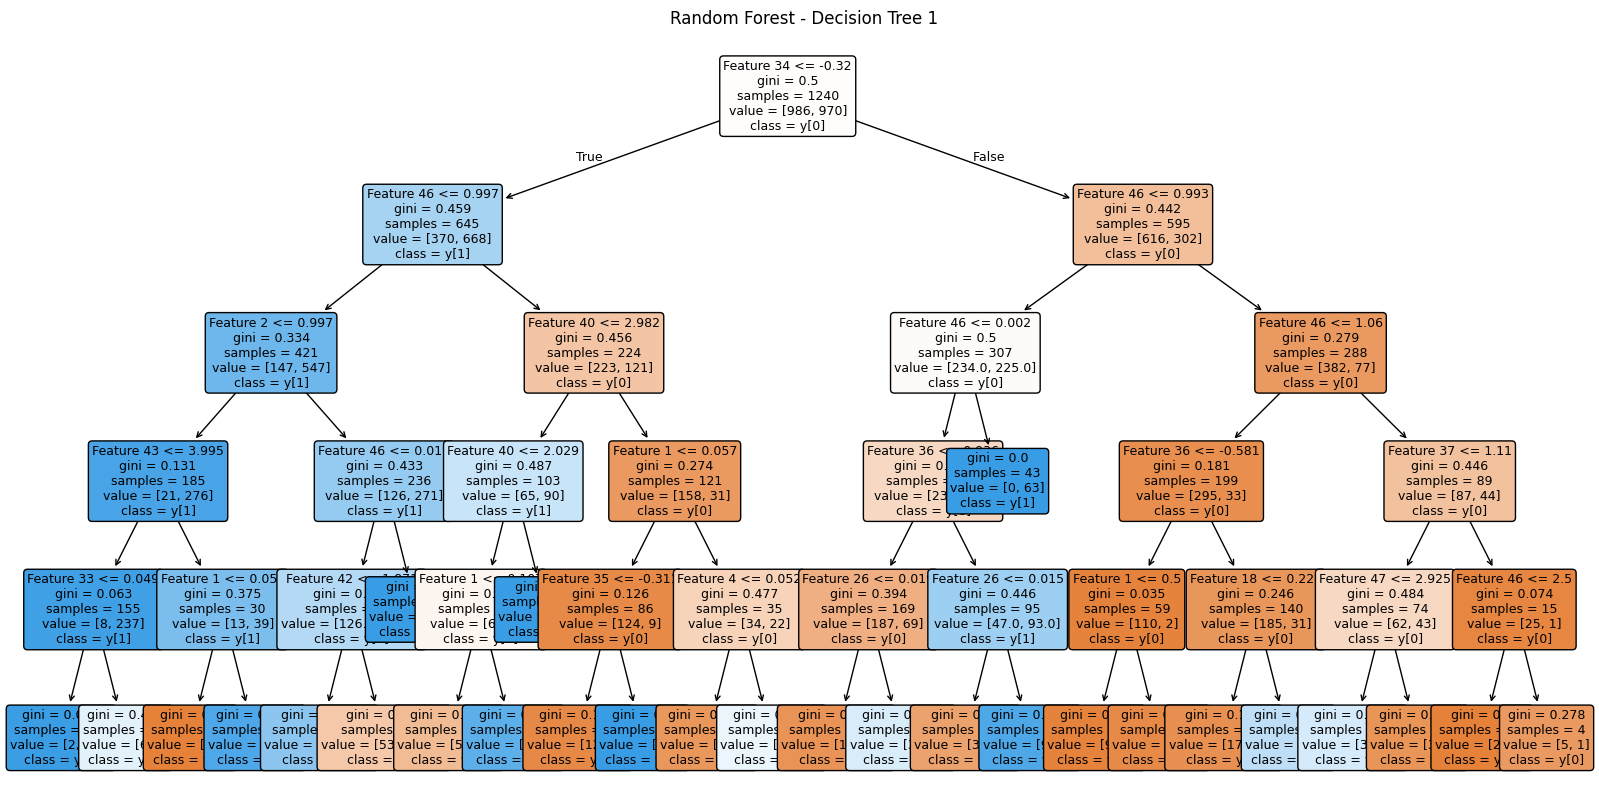

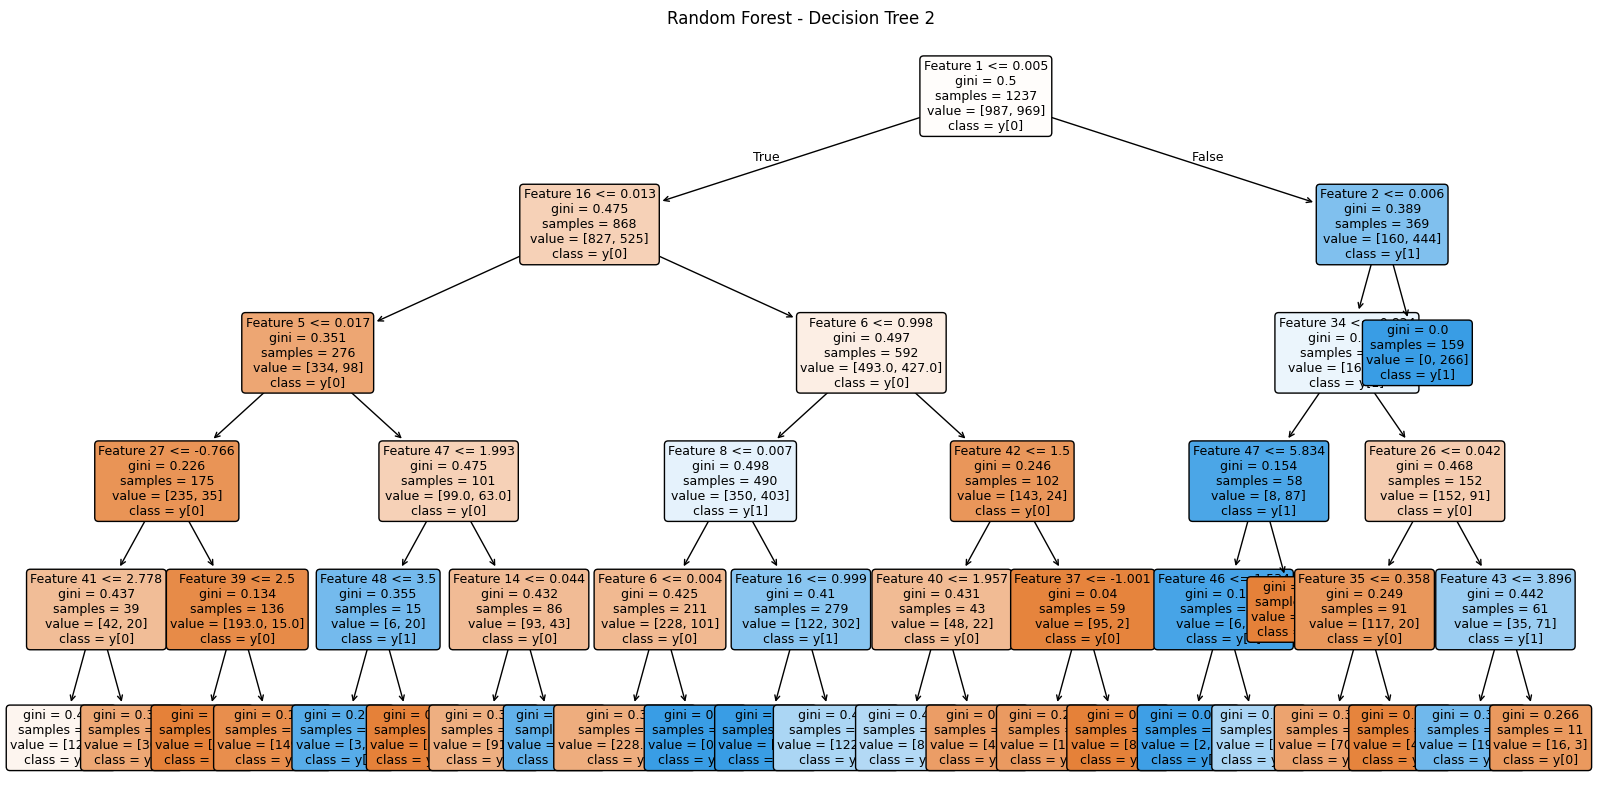

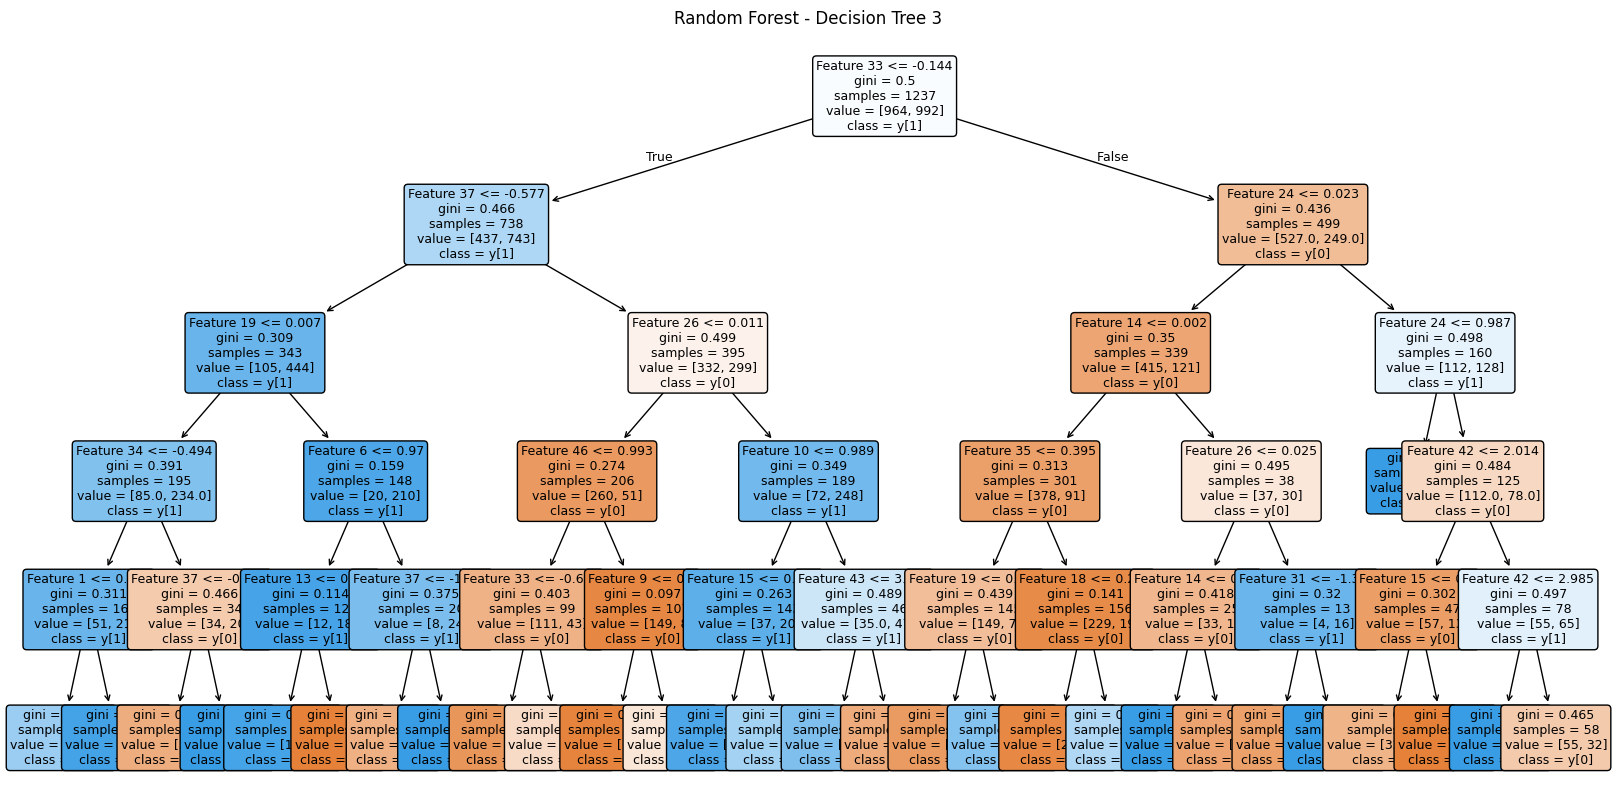

In [52]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

for i in range(3):

    plt.figure(figsize=(20, 10))

    plot_tree(
        random_forest_model.estimators_[i],
        feature_names=[f"Feature {j}" for j in range(x_sm.shape[1])],
        class_names=True,
        filled=True,
        rounded=True,
        fontsize=9
    )

    plt.title(f"Random Forest - Decision Tree {i+1}")
    plt.show()


# 12. Model 5 – Gradient Boosting
Trees are built **one after another**, and each new tree corrects the errors of the previous ones.

![boosting Block Diagram](boosting.jpeg)

In [17]:
gradient_boosting_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gradient_boosting_model.fit(x_sm, y_sm)

print("Train Accuracy:", accuracy_score(y_sm, gradient_boosting_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, gradient_boosting_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, gradient_boosting_model.predict(processed_x_test)))

Train Accuracy: 0.9667689161554193
Test  Accuracy: 0.8775510204081632

Classification Report

              precision    recall  f1-score   support

           0       0.91      0.96      0.93       255
           1       0.56      0.36      0.44        39

    accuracy                           0.88       294
   macro avg       0.73      0.66      0.68       294
weighted avg       0.86      0.88      0.87       294



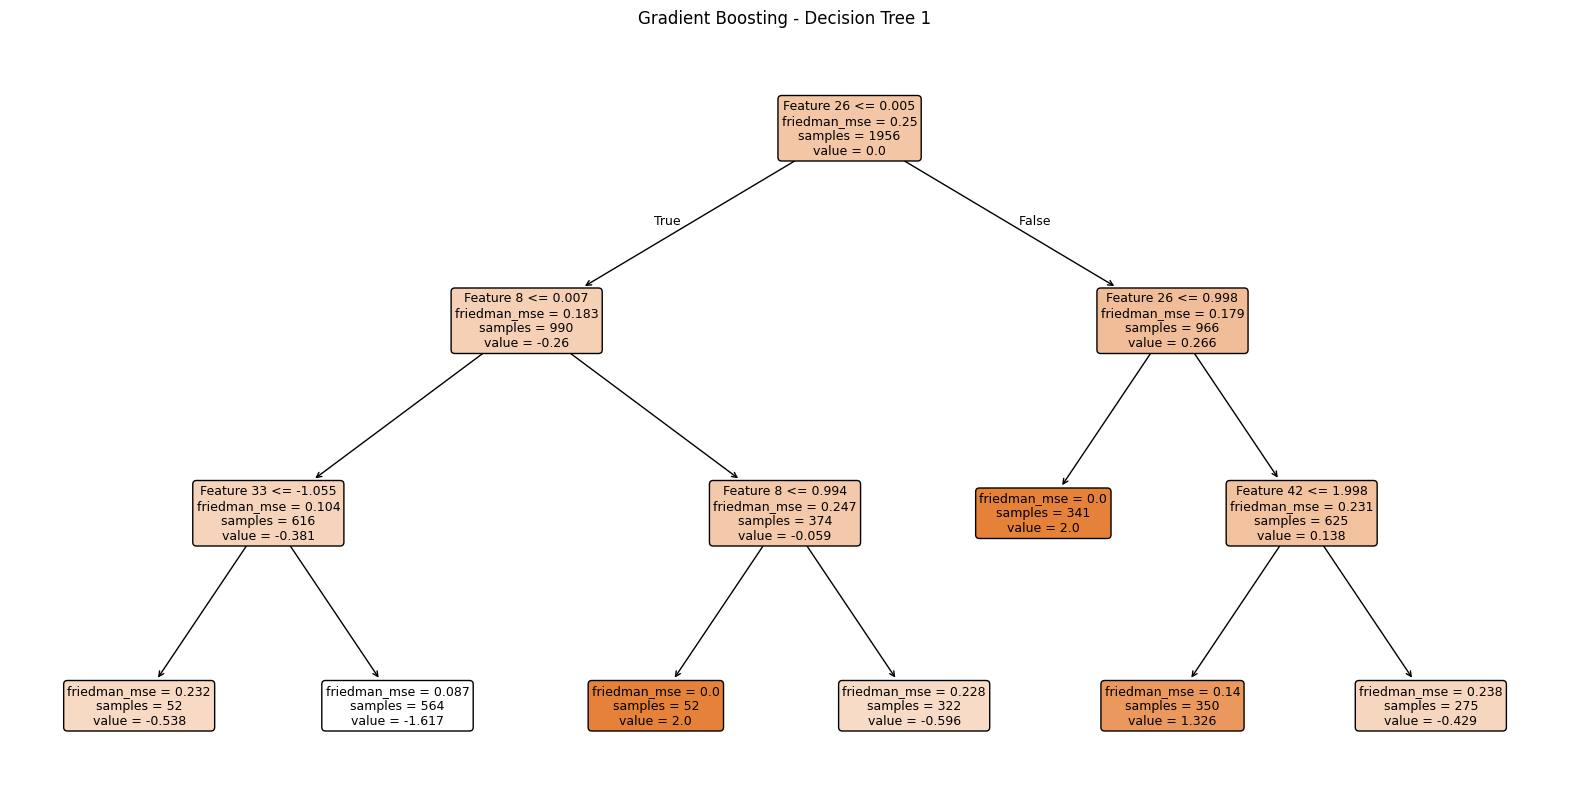

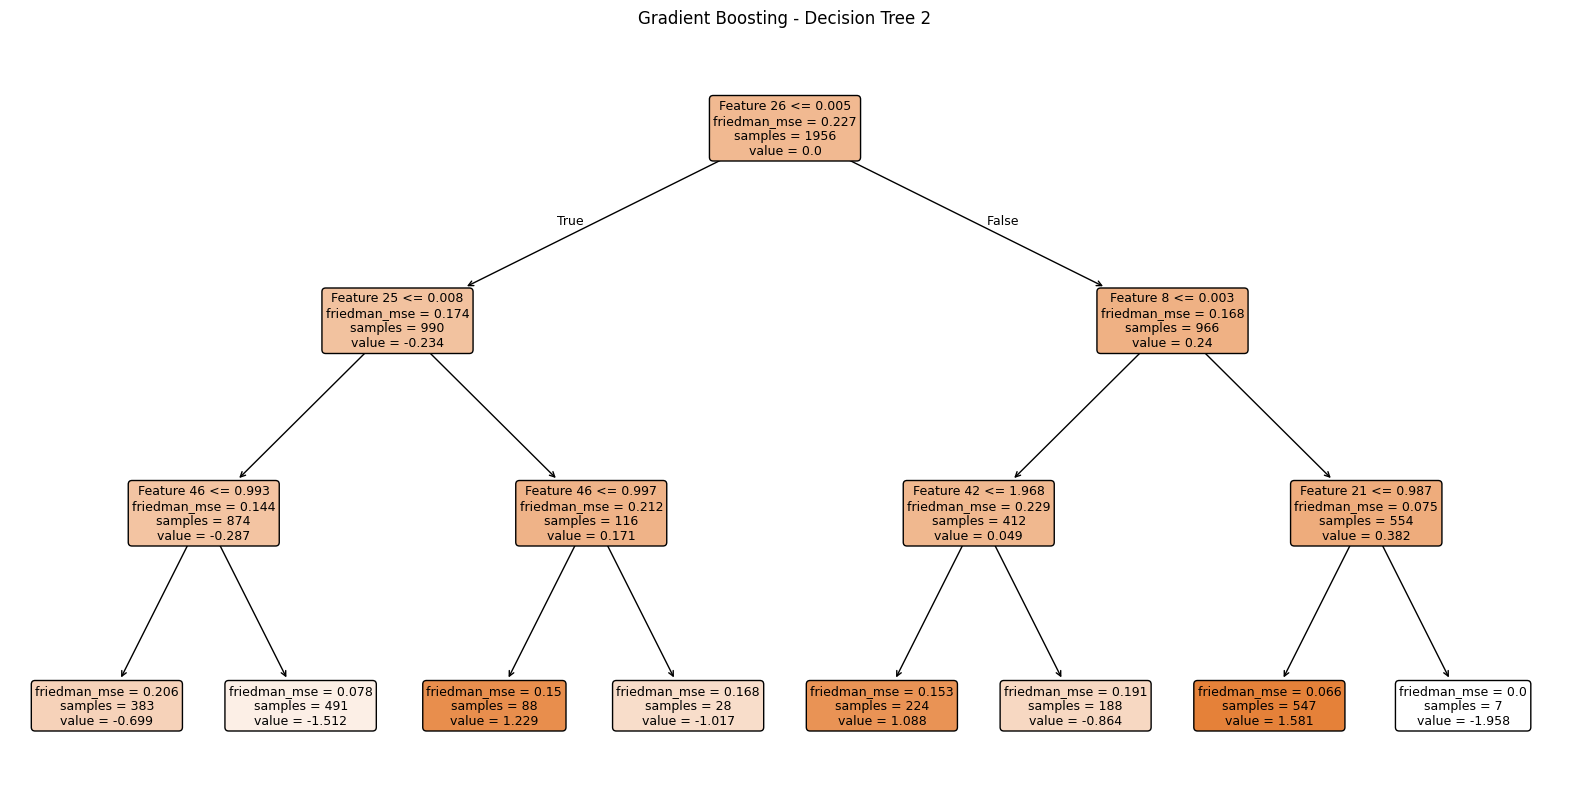

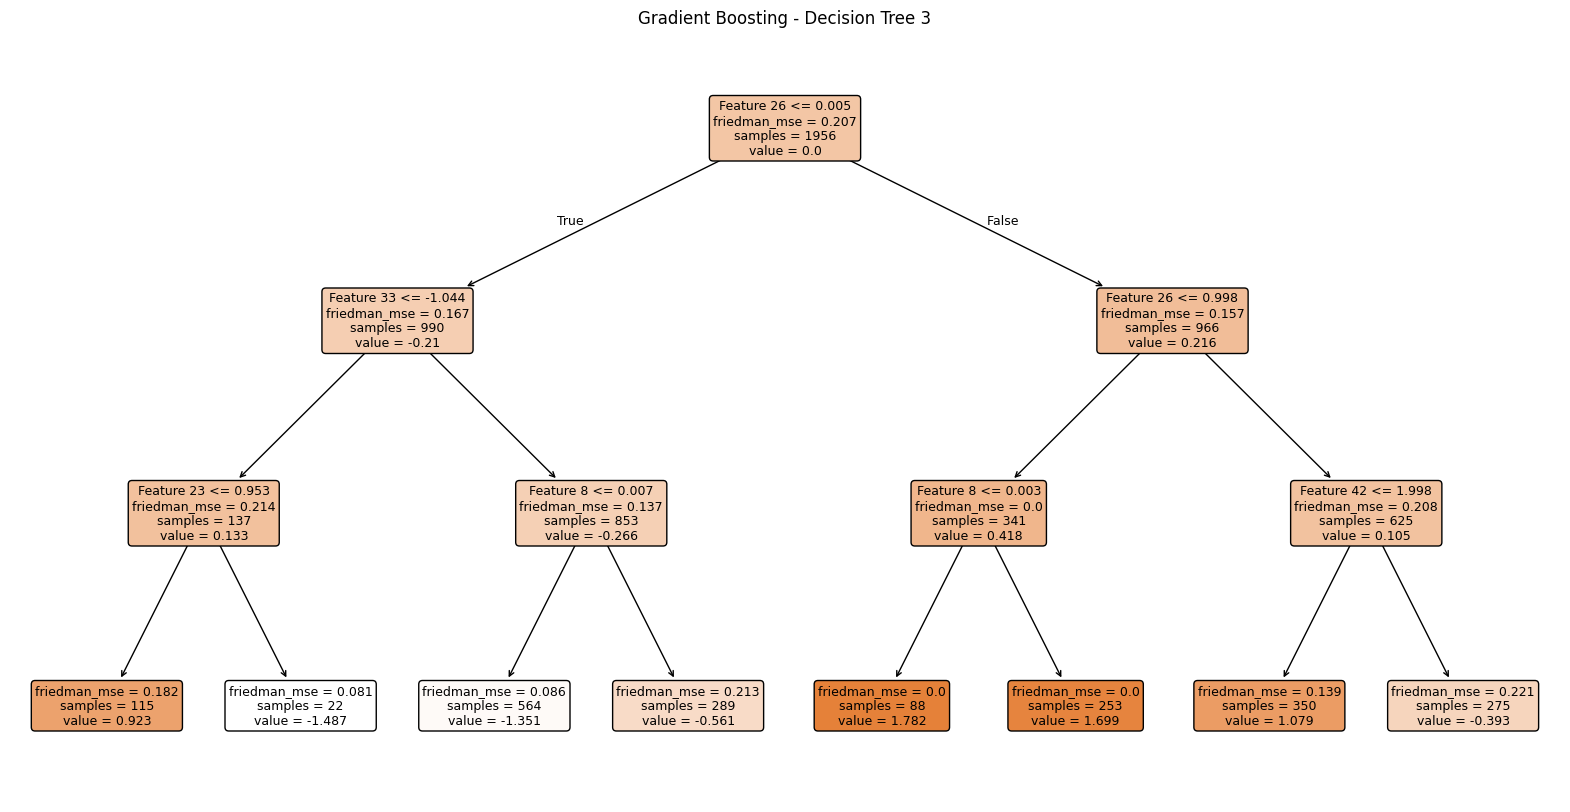

In [50]:

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

for i in range(3):

    plt.figure(figsize=(20, 10))

    plot_tree(
        gradient_boosting_model.estimators_[i, 0],
        feature_names=[f"Feature {j}" for j in range(x_sm.shape[1])],
        filled=True,
        rounded=True,
        fontsize=9
    )

    plt.title(f"Gradient Boosting - Decision Tree {i+1}")
    plt.show()


# 13. Model 6 – XGBoost
An optimized and regularized version of gradient boosting – faster and usually more accurate.

In [48]:
xgboost_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
xgboost_model.fit(x_sm, y_sm)

print("Train Accuracy:", accuracy_score(y_sm, xgboost_model.predict(x_sm)))
print("Test  Accuracy:", accuracy_score(y_test, xgboost_model.predict(processed_x_test)))
print("\nClassification Report\n")
print(classification_report(y_test, xgboost_model.predict(processed_x_test)))

Train Accuracy: 0.9948875255623721
Test  Accuracy: 0.8843537414965986

Classification Report

              precision    recall  f1-score   support

           0       0.90      0.98      0.94       255
           1       0.67      0.26      0.37        39

    accuracy                           0.88       294
   macro avg       0.78      0.62      0.65       294
weighted avg       0.87      0.88      0.86       294



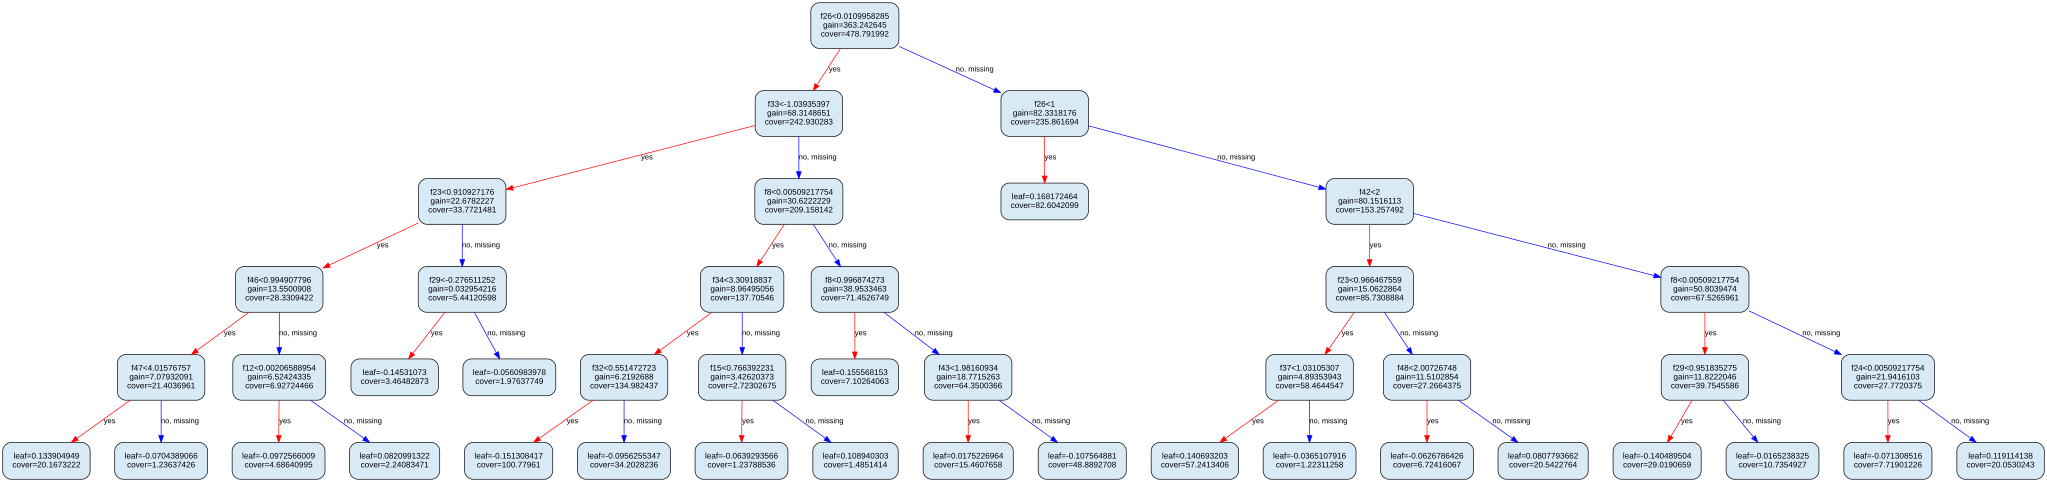

In [51]:

from xgboost import to_graphviz
from graphviz import Source
from IPython.display import display, SVG

tree = to_graphviz(
    xgboost_model,
    num_trees=2,
    rankdir='TB',
    with_stats=True
)

dot = tree.source.replace(
    'digraph {',
    '''digraph {
    graph [rankdir=TB, nodesep=0.5, ranksep=0.7, bgcolor="white"];
    node [shape=box, style="rounded,filled", fillcolor="#D9EAF7",
          fontname="Arial", fontsize=12, margin=0.2];
    edge [fontname="Arial", fontsize=11];
    '''
)

display(SVG(Source(dot).pipe(format='svg')))


# 14. Final Model Comparison

**How to read the Train–Test accuracy gap**

| Difference in Train & Test Accuracy | Interpretation     |
| ----------------------------------- | ------------------ |
| 0% to 5%                            | Very Good Model    |
| 5% to 10%                           | Acceptable         |
| 10% to 15%                          | Slight Overfitting |
| More than 15%                       | Strong Overfitting |

| Model             | Train Accuracy | Test Accuracy | Difference | Performance           |
| ----------------- | -------------- | ------------- | ---------- | --------------------- |
| Decision Tree     | 88.44%         | 79.93%        | 9%         | Acceptable            |
| Tuned DT          | 98.16%         | 81.29%        | 17%        | Overfitting           |
| Bagging           | 100%           | 85.71%        | 15%        | Slight Overfitting    |
| Random Forest     | 99%            | 86%           | 13%        | Better Generalization |
| Gradient Boosting | 96.67%         | 87.76%        | 9%         | Good Generalization   |
| XGBoost           | 96.37%         | 89.12%        | 7%         | Best Model            |


In [28]:
!pip install graphviz
